# H16: H&E Spleen Follicle Genotype Comparison

**Cohort:** 27 donors (9 C/C, 9 C/T, 9 T/T) with H&E-stained spleen sections, 1–4 images per donor (68 total).

**Data:** `27_donor_spleen_measurements1.csv` (QuPath Follicle/Tissue segmentation) joined with `Spleen_rs3184504_Genotypes.xlsx`.

**Unit of analysis:** per-donor (mean across each donor's images). Strict n=27.

**Limitations vs fluorescent cohort:** No SmallVessel detection (H&E lacks marker channels), no PALS/RedPulp/Trabeculae sub-regions, no marker intensities. Available features: Area, Perimeter, Centroid X/Y per Follicle annotation; one Tissue annotation per image (whole-section boundary).

**Pipeline:**
1. Setup & data loading (`BASE_TRIM`, `MIN_TRIM`, `MAX_TRIM` knobs defined here)
2. Data quality (per-donor SE-driven percentile trim on linear µm²: tight image-to-image SE → light trim; noisy SE → heavy trim)
3. Per-image and per-donor aggregates
4. Simple genotype comparisons (5 metrics + Kruskal-Wallis / Mann-Whitney / Spearman dosage)
5. Detailed analyses (mirror H3/H4/H5 patterns)
6. Summary

## 1. Setup & data loading

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial import cKDTree

from data_utils import (
    GENO_ORDER, GENO_PALETTE,
    setup_style, save_figure, save_table,
    full_stats_table, run_kruskal, run_pairwise, run_dosage_trend,
    _normalize_genotype, extract_sample_id, CODE_ROOT,
)

setup_style()

HE_CSV = CODE_ROOT / '27_donor_spleen_measurements1.csv'
HE_GENO_XLSX = CODE_ROOT / 'Spleen_rs3184504_Genotypes.xlsx'

# SE-driven per-donor area trim (see section 2):
# trim_frac_donor = clip(donor_SE / ref_SE * BASE_TRIM, MIN_TRIM, MAX_TRIM).
# Each donor's lower/upper cutoffs are the trim_frac and (1 - trim_frac) quantiles
# of that donor's own follicle area distribution (linear µm², no log transform).
BASE_TRIM = 0.05   # trim fraction at the cohort's reference (mean) donor SE
MIN_TRIM  = 0.005  # floor for very-consistent donors (small SE)
MAX_TRIM  = 0.20   # ceiling for very-variable donors (large SE)

print(f'Code root: {CODE_ROOT}')
print(f'CSV exists: {HE_CSV.exists()}')
print(f'Genotype Excel exists: {HE_GENO_XLSX.exists()}')

Project: /blue/maigan/smith6jt/SpleenFollicleCounterQP
CSV exists: True
Genotype Excel exists: True


In [2]:
def load_he_genotypes():
    g = pd.read_excel(HE_GENO_XLSX)
    geno_col = next(c for c in g.columns if 'rs3184504' in c)
    g['Sample'] = g['Sample ID'].astype(str).str.strip()
    g['Genotype'] = g[geno_col].apply(_normalize_genotype)
    return dict(zip(g['Sample'], g['Genotype']))


def extract_he_sample(image_name: str) -> str:
    return extract_sample_id(image_name)


geno_map = load_he_genotypes()
print(f'Loaded {len(geno_map)} samples from genotype file')
print(f'Genotype distribution (full file): {pd.Series(geno_map).value_counts().to_dict()}')

Loaded 95 samples from genotype file
Genotype distribution (full file): {'C/T': 44, 'C/C': 42, 'T/T': 9}


In [3]:
raw = pd.read_csv(HE_CSV)
raw['Sample'] = raw['Image'].apply(extract_he_sample)
raw['Genotype'] = raw['Sample'].map(geno_map)

print(f'Annotations: {len(raw):,}')
print(f'Images: {raw["Image"].nunique()}')
print(f'Donors: {raw["Sample"].nunique()}')
print(f'Donors without genotype: {raw[raw["Genotype"].isna()]["Sample"].unique().tolist()}')
print(f'Classifications: {raw["Classification"].value_counts().to_dict()}')

Annotations: 6,714
Images: 68
Donors: 27
Donors without genotype: []
Classifications: {'Follicle': 6646, 'Tissue': 68}


In [4]:
# Cohort summary: donors per genotype, images per donor
cohort = raw.drop_duplicates('Sample')[['Sample', 'Genotype']].copy()
img_per_donor = raw.groupby('Sample', observed=True)['Image'].nunique().rename('N_images')
cohort = cohort.merge(img_per_donor, left_on='Sample', right_index=True)

print('Donors per genotype:')
print(cohort['Genotype'].value_counts().reindex(GENO_ORDER))
print('\nImages per donor distribution:')
print(cohort['N_images'].value_counts().sort_index())
print(f'\nTotal images: {cohort["N_images"].sum()}')

save_table(cohort.sort_values(['Genotype', 'Sample']), 'HE_cohort_summary')

Donors per genotype:
Genotype
C/C    9
C/T    9
T/T    9
Name: count, dtype: int64

Images per donor distribution:
N_images
1     3
2     8
3    15
4     1
Name: count, dtype: int64

Total images: 68
Saved: analysis/tables/HE_cohort_summary.csv


## 2. Data quality

Reference SE (mean across donors): 20357 µm²
BASE_TRIM=0.05, clamp=[0.005, 0.2], fallback SE (1-image donors)=15792 µm²

Per-donor cutoffs (µm²):
Sample Genotype  n_images  donor_mean  img_se_used  trim_frac  LOW_um2  HIGH_um2
HDL004      C/C         1    121293.0      15792.0     0.0388  14035.0  412850.0
HDL005      C/C         3    104946.0       7786.0     0.0191  10585.0  525070.0
HDL009      T/T         3    136375.0      22083.0     0.0542  14889.0  340878.0
HDL013      C/C         2     78533.0        853.0     0.0050  10533.0  277632.0
HDL014      T/T         2    184642.0      42549.0     0.1045  28163.0  402318.0
HDL029      T/T         2    135042.0      14787.0     0.0363  13092.0  439147.0
HDL031      C/T         3    178062.0      18972.0     0.0466  15338.0  431172.0
HDL036      C/C         2    100942.0      16796.0     0.0413  11011.0  320883.0
HDL049      C/T         3    168525.0     104312.0     0.2000  24225.0  154089.0
HDL055      C/C         3    148658.0       

/tmp/ipykernel_1833987/3148494366.py:179: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved: analysis/figures/HE_area_filter_diagnostic.png


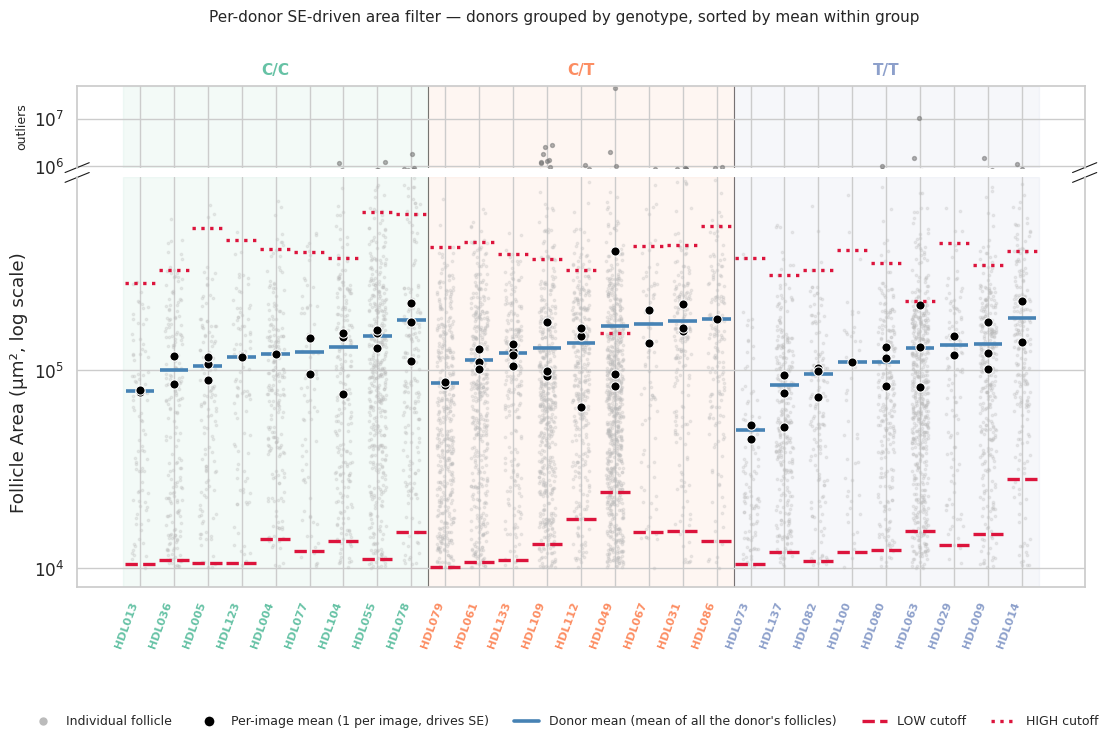

Saved: analysis/tables/HE_per_donor_drop_counts.csv

Per-donor drop counts:
Sample Genotype  n_images     SE  trim_frac  LOW_um2  HIGH_um2  n_total  drop_low  drop_high  kept
HDL004      C/C         1  15792     0.0388    14035    412850      199         8          8   183
HDL005      C/C         3   7786     0.0191    10585    525070      120         3          3   114
HDL009      T/T         3  22083     0.0542    14889    340878      321        18         18   285
HDL013      C/C         2    853     0.0050    10533    277632       89         1          1    87
HDL014      T/T         2  42549     0.1045    28163    402318      214        23         23   168
HDL029      T/T         2  14787     0.0363    13092    439147      108         3          4   101
HDL031      C/T         3  18972     0.0466    15338    431172      191         9          9   173
HDL036      C/C         2  16796     0.0413    11011    320883      196         9          9   178
HDL049      C/T         3 104312 

In [5]:
follicles_all = raw[raw['Classification'] == 'Follicle'].copy()
tissue_all = raw[raw['Classification'] == 'Tissue'].copy()

# --- Per-donor SE on linear µm² (donor mean & SE of per-image mean areas) ---
img_mean_df = (follicles_all
               .groupby(['Image', 'Sample'], observed=True)['Area µm^2']
               .mean()
               .reset_index()
               .rename(columns={'Area µm^2': 'image_mean'}))

donor_stats = (img_mean_df
               .groupby('Sample', observed=True)['image_mean']
               .agg(img_sd='std', n_images='count')
               .reset_index())
donor_stats['img_se'] = donor_stats['img_sd'] / np.sqrt(donor_stats['n_images'])

# Donor's follicle-level arithmetic mean (mean of every individual follicle).
donor_stats['donor_mean'] = donor_stats['Sample'].map(
    follicles_all.groupby('Sample', observed=True)['Area µm^2'].mean()
)

# Donor genotype (for grouping along the x-axis).
geno_per_sample = (follicles_all.drop_duplicates('Sample')
                                .set_index('Sample')['Genotype']
                                .astype(str))
donor_stats['Genotype'] = donor_stats['Sample'].map(geno_per_sample)

# Fallback SE for 1-image donors: median SE across multi-image donors
fallback_se = float(donor_stats.loc[donor_stats['n_images'] > 1, 'img_se'].median())
donor_stats['img_se_used'] = donor_stats['img_se'].fillna(fallback_se)

# Map SE → trim fraction. Low SE → tiny trim; high SE → heavy trim.
ref_se = float(donor_stats['img_se_used'].mean())
donor_stats['trim_frac'] = (
    (donor_stats['img_se_used'] / ref_se) * BASE_TRIM
).clip(MIN_TRIM, MAX_TRIM)

# Per-donor cutoffs = quantiles of the donor's own follicle areas
low_q  = lambda g, p: float(g['Area µm^2'].quantile(p))
hi_q   = lambda g, p: float(g['Area µm^2'].quantile(1 - p))
donor_stats['LOW_um2']  = [low_q(follicles_all[follicles_all['Sample'] == s], p)
                            for s, p in zip(donor_stats['Sample'], donor_stats['trim_frac'])]
donor_stats['HIGH_um2'] = [hi_q(follicles_all[follicles_all['Sample'] == s], p)
                            for s, p in zip(donor_stats['Sample'], donor_stats['trim_frac'])]

print(f'Reference SE (mean across donors): {ref_se:.0f} µm²')
print(f'BASE_TRIM={BASE_TRIM}, clamp=[{MIN_TRIM}, {MAX_TRIM}], '
      f'fallback SE (1-image donors)={fallback_se:.0f} µm²')
print('\nPer-donor cutoffs (µm²):')
print(donor_stats[['Sample', 'Genotype', 'n_images', 'donor_mean', 'img_se_used',
                   'trim_frac', 'LOW_um2', 'HIGH_um2']]
      .round({'donor_mean': 0, 'img_se_used': 0, 'trim_frac': 4,
              'LOW_um2': 0, 'HIGH_um2': 0})
      .to_string(index=False))

save_table(donor_stats[['Sample', 'Genotype', 'n_images', 'donor_mean',
                        'img_sd', 'img_se', 'img_se_used',
                        'trim_frac', 'LOW_um2', 'HIGH_um2']],
           'HE_per_donor_area_cutoffs')

# --- Diagnostic plot: donors organized by genotype (C/C, C/T, T/T) ---
# Within each genotype, sorted by donor_mean ascending so the trend within
# group is still visible. X-tick labels are colored by genotype; vertical
# separators mark the C/C | C/T | T/T boundaries.
donor_stats['_geno_rank'] = donor_stats['Genotype'].map(
    {g: i for i, g in enumerate(GENO_ORDER)})
order = donor_stats.sort_values(['_geno_rank', 'donor_mean'])['Sample'].tolist()
sample_idx = {s: i for i, s in enumerate(order)}

break_low  = float(max(donor_stats['HIGH_um2'].max(),
                       img_mean_df['image_mean'].max())) * 1.5
break_high = float(follicles_all['Area µm^2'].max()) * 1.1
y_bottom   = float(follicles_all['Area µm^2'].min()) * 0.8

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(13, 7.6), sharex=True,
    gridspec_kw={'height_ratios': [1, 5], 'hspace': 0.04},
)

# Genotype-group background shading + boundaries
group_bounds = []  # (start_idx, end_idx, genotype)
i = 0
while i < len(order):
    g = geno_per_sample[order[i]]
    j = i
    while j < len(order) and geno_per_sample[order[j]] == g:
        j += 1
    group_bounds.append((i, j - 1, g))
    i = j

for start, end, g in group_bounds:
    color = GENO_PALETTE[g]
    for ax in (ax_top, ax_bot):
        ax.axvspan(start - 0.5, end + 0.5, color=color, alpha=0.08, zorder=0)
# Boundary lines between groups
for start, end, g in group_bounds[:-1]:
    for ax in (ax_top, ax_bot):
        ax.axvline(end + 0.5, color='black', lw=0.8, alpha=0.5, zorder=0)

rng = np.random.RandomState(0)
for s in order:
    sub = follicles_all[follicles_all['Sample'] == s]
    x = sample_idx[s] + (rng.rand(len(sub)) - 0.5) * 0.5
    ax_bot.scatter(x, sub['Area µm^2'], s=3, color='#bbb', alpha=0.25,
                   rasterized=True, zorder=1)
    ax_top.scatter(x, sub['Area µm^2'], s=8, color='#777', alpha=0.55,
                   rasterized=True, zorder=1)

# Per-image mean (black dots) — these drive the SE used for trim fraction.
for s in order:
    img_means_s = img_mean_df[img_mean_df['Sample'] == s]['image_mean'].values
    xs = np.full(len(img_means_s), sample_idx[s])
    ax_bot.scatter(xs, img_means_s, s=44, color='black', edgecolor='white',
                   linewidth=0.8, zorder=5, marker='o')

# Donor mean (blue) — mean of all of the donor's individual follicles.
for _, row in donor_stats.iterrows():
    i = sample_idx[row['Sample']]
    ax_bot.plot([i - 0.42, i + 0.42], [row['donor_mean']] * 2,
                color='steelblue', lw=2.6, zorder=4, solid_capstyle='butt')

# Quantile cutoffs (red), on top of everything.
for _, row in donor_stats.iterrows():
    i = sample_idx[row['Sample']]
    ax_bot.plot([i - 0.45, i + 0.45], [row['LOW_um2']] * 2,
                color='crimson', lw=2.4, ls='--', zorder=6, solid_capstyle='butt')
    ax_bot.plot([i - 0.45, i + 0.45], [row['HIGH_um2']] * 2,
                color='crimson', lw=2.4, ls=':', zorder=6, solid_capstyle='butt')

ax_bot.set_yscale('log')
ax_bot.set_ylim(y_bottom, break_low)
ax_top.set_yscale('log')
ax_top.set_ylim(break_low, break_high)

ax_top.spines['bottom'].set_visible(False)
ax_bot.spines['top'].set_visible(False)
ax_top.tick_params(axis='x', which='both', length=0, labelbottom=False)
d = 0.012
kwargs = dict(transform=ax_top.transAxes, color='k', clip_on=False, lw=0.8)
ax_top.plot((-d, +d), (-d * 5, +d * 5), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d * 5, +d * 5), **kwargs)
kwargs.update(transform=ax_bot.transAxes)
ax_bot.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bot.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

# Genotype labels above the outlier strip, centered over each group.
for start, end, g in group_bounds:
    mid = (start + end) / 2
    ax_top.text(mid, 1.10, g, transform=ax_top.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                color=GENO_PALETTE[g])

ax_bot.set_xticks(range(len(order)))
ax_bot.set_xticklabels(order, rotation=70, ha='right', fontsize=8)
# Color the x-tick labels by genotype
for tick, sample in zip(ax_bot.get_xticklabels(), order):
    g = geno_per_sample[sample]
    tick.set_color(GENO_PALETTE[g])
    tick.set_fontweight('bold')

ax_bot.set_ylabel('Follicle Area (µm², log scale)')
ax_top.set_ylabel('outliers', fontsize=9)
fig.suptitle('Per-donor SE-driven area filter — donors grouped by genotype, sorted by mean within group',
             y=0.98, fontsize=11)

# Legend below the plot, with generous space from the rotated x-tick labels.
from matplotlib.lines import Line2D
legend_items = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#bbb',
           markeredgecolor='#bbb', markersize=5, label='Individual follicle'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='black',
           markeredgecolor='white', markersize=8,
           label='Per-image mean (1 per image, drives SE)'),
    Line2D([0], [0], color='steelblue', lw=2.6,
           label="Donor mean (mean of all the donor's follicles)"),
    Line2D([0], [0], color='crimson', lw=2.4, ls='--', label='LOW cutoff'),
    Line2D([0], [0], color='crimson', lw=2.4, ls=':',  label='HIGH cutoff'),
]
fig.tight_layout()
fig.subplots_adjust(bottom=0.22, top=0.88)
fig.legend(handles=legend_items, loc='lower center', ncol=5,
           bbox_to_anchor=(0.5, 0.02), fontsize=9, frameon=False)
save_figure(fig, 'HE_area_filter_diagnostic')
plt.show()

# --- Build the keep mask + per-donor drop summary ---
keep_mask = pd.Series(False, index=follicles_all.index)
drop_rows = []
for _, row in donor_stats.iterrows():
    sub = follicles_all[follicles_all['Sample'] == row['Sample']]
    in_band = (sub['Area µm^2'] >= row['LOW_um2']) & (sub['Area µm^2'] <= row['HIGH_um2'])
    keep_mask.loc[sub.index] = in_band
    n_lo = int((sub['Area µm^2'] < row['LOW_um2']).sum())
    n_hi = int((sub['Area µm^2'] > row['HIGH_um2']).sum())
    drop_rows.append({
        'Sample': row['Sample'], 'Genotype': row['Genotype'],
        'n_images': int(row['n_images']),
        'SE': round(row['img_se_used']), 'trim_frac': round(row['trim_frac'], 4),
        'LOW_um2': round(row['LOW_um2']), 'HIGH_um2': round(row['HIGH_um2']),
        'n_total': len(sub), 'drop_low': n_lo, 'drop_high': n_hi,
        'kept': len(sub) - n_lo - n_hi,
    })
drop_summary = pd.DataFrame(drop_rows)
save_table(drop_summary, 'HE_per_donor_drop_counts')
print('\nPer-donor drop counts:')
print(drop_summary.to_string(index=False))

n_total = len(follicles_all)
n_keep  = int(keep_mask.sum())
print(f'\nOverall: dropped {drop_summary["drop_low"].sum()} below LOW, '
      f'{drop_summary["drop_high"].sum()} above HIGH, '
      f'retained {n_keep} of {n_total:,} ({n_keep/n_total*100:.1f}%)')


In [6]:
follicles = follicles_all[keep_mask].copy()
follicles = follicles.dropna(subset=['Genotype'])
follicles['Genotype'] = pd.Categorical(follicles['Genotype'], categories=GENO_ORDER, ordered=True)

# Circularity = 4π·Area / Perimeter² — perfect circle = 1
follicles['Circularity'] = (
    4 * np.pi * follicles['Area µm^2'] / follicles['Perimeter µm'].replace(0, np.nan) ** 2
)

tissue = tissue_all.dropna(subset=['Genotype']).copy()
tissue['Genotype'] = pd.Categorical(tissue['Genotype'], categories=GENO_ORDER, ordered=True)

print(f'Retained follicles: {len(follicles):,}')
print(f'Retained tissue annotations: {len(tissue):,}')
print(f'Circularity range: [{follicles["Circularity"].min():.3f}, {follicles["Circularity"].max():.3f}]')

save_table(follicles, 'HE_follicles_filtered')

Retained follicles: 5,785
Retained tissue annotations: 68
Circularity range: [0.034, 0.578]
Saved: analysis/tables/HE_follicles_filtered.csv


### Robustness check: random 1-image-per-donor subset

Pick a single image at random for each donor (seeded) and rerun the same diagnostic. With only one image per donor there is no within-donor SE, so every donor falls back to the median multi-image SE → a uniform trim fraction across donors. The blue line collapses to that image's follicle mean and the black dot to the donor's only image-mean.

Subset: 1 image per donor, seed=20260511
Total follicles in subset: 2,585 (vs 6,646 in full data)

All donors get trim_frac=0.0500 (uniform; SE collapsed to fallback 15792 µm²)


/tmp/ipykernel_1833987/3157124342.py:145: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved: analysis/figures/HE_area_filter_diagnostic_1img_per_donor.png


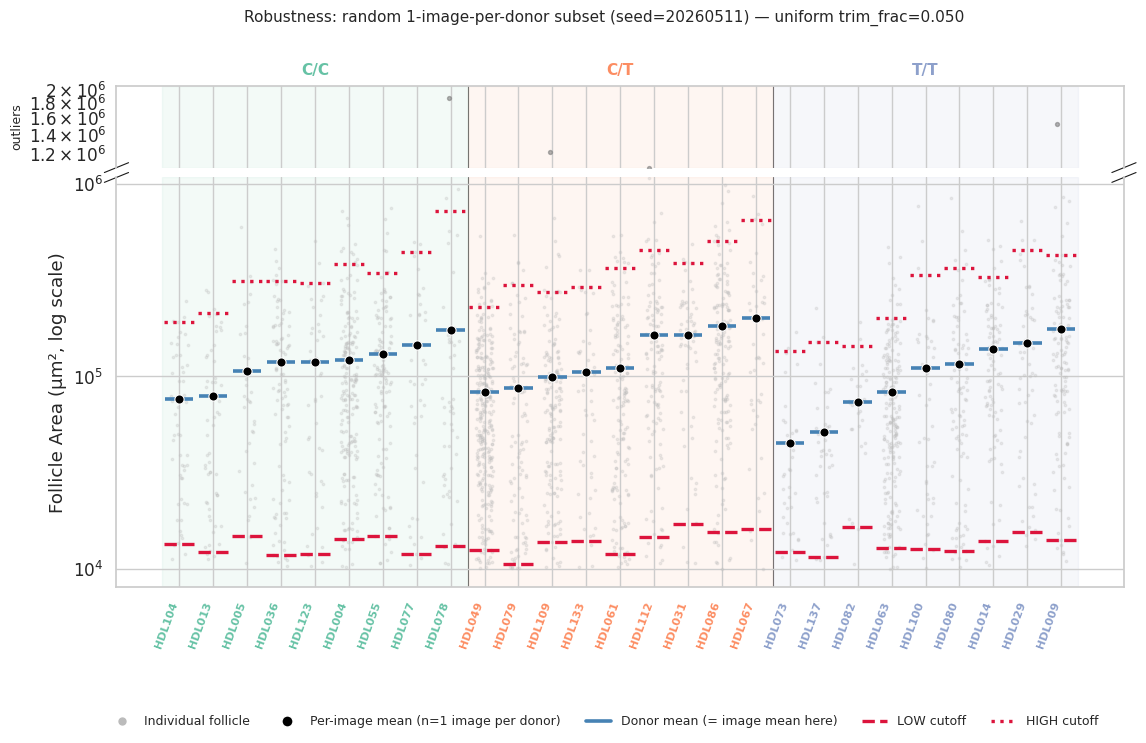


Picked image per donor:
  HDL104 (C/C): HDL104_Spleen_HxE_1_174942_normalized.ome.tif - normalized
  HDL013 (C/C): HDL013_Spleen_HxE_2_128261_normalized.ome.tif - normalized
  HDL005 (C/C): HDL005_Spleen_HxE_2_121865_normalized.ome.tif - normalized
  HDL036 (C/C): HDL036_Spleen_HxE_1_136842_normalized.ome.tif - normalized
  HDL123 (C/C): HDL123_Spleen_HxE_1_178629_normalized.ome.tif - normalized
  HDL004 (C/C): HDL004_Spleen_HxE_2_95738_normalized.ome.tif - normalized
  HDL055 (C/C): HDL055_Spleen_HxE_3_141323_normalized.ome.tif - normalized
  HDL077 (C/C): HDL077_Spleen_HxE_3_163916_normalized.ome.tif - normalized
  HDL078 (C/C): HDL078_Spleen_HxE_2_163924_normalized.ome.tif - normalized
  HDL049 (C/T): HDL049_Spleen_HxE_2_162664_normalized.ome.tif - normalized
  HDL079 (C/T): HDL079_Spleen_HxE_1_164839_normalized.ome.tif - normalized
  HDL109 (C/T): HDL109_Spleen_HxE_2_176162_normalized.ome.tif - normalized
  HDL133 (C/T): HDL133_Spleen_HxE_2_179858_normalized.ome.tif - normalized
 

In [7]:
SUBSET_SEED = 20260511
rng_pick = np.random.default_rng(SUBSET_SEED)

# Random 1-image-per-donor subset (1 row of follicles_all per Sample's chosen Image).
images_per_donor = (follicles_all.groupby('Sample', observed=True)['Image']
                                  .unique().to_dict())
picked_image = {s: imgs[rng_pick.integers(0, len(imgs))]
                for s, imgs in images_per_donor.items()}
sub_all = follicles_all[follicles_all.apply(
    lambda r: r['Image'] == picked_image[r['Sample']], axis=1)].copy()
print(f'Subset: 1 image per donor, seed={SUBSET_SEED}')
print(f'Total follicles in subset: {len(sub_all):,} '
      f'(vs {len(follicles_all):,} in full data)')

# Per-donor stats on the subset. With n_images=1 everywhere, SE is undefined,
# so every donor uses the fallback SE from the full-data multi-image donors.
img_mean_sub = (sub_all.groupby(['Image', 'Sample'], observed=True)['Area µm^2']
                       .mean().reset_index()
                       .rename(columns={'Area µm^2': 'image_mean'}))
donor_sub = (img_mean_sub.groupby('Sample', observed=True)['image_mean']
                          .agg(n_images='count').reset_index())
donor_sub['img_se_used'] = fallback_se  # uniform across donors

donor_sub['donor_mean'] = donor_sub['Sample'].map(
    sub_all.groupby('Sample', observed=True)['Area µm^2'].mean())
donor_sub['Genotype'] = donor_sub['Sample'].map(geno_per_sample)

ref_se_sub = float(donor_sub['img_se_used'].mean())
donor_sub['trim_frac'] = (
    (donor_sub['img_se_used'] / ref_se_sub) * BASE_TRIM
).clip(MIN_TRIM, MAX_TRIM)
donor_sub['LOW_um2']  = [low_q(sub_all[sub_all['Sample'] == s], p)
                          for s, p in zip(donor_sub['Sample'], donor_sub['trim_frac'])]
donor_sub['HIGH_um2'] = [hi_q(sub_all[sub_all['Sample'] == s], p)
                          for s, p in zip(donor_sub['Sample'], donor_sub['trim_frac'])]
donor_sub['_geno_rank'] = donor_sub['Genotype'].map(
    {g: i for i, g in enumerate(GENO_ORDER)})

print(f"\nAll donors get trim_frac={donor_sub['trim_frac'].iloc[0]:.4f} "
      f"(uniform; SE collapsed to fallback {fallback_se:.0f} µm²)")

# Diagnostic plot with same structure as section 2
order_sub = donor_sub.sort_values(['_geno_rank', 'donor_mean'])['Sample'].tolist()
sample_idx_sub = {s: i for i, s in enumerate(order_sub)}

break_low_s  = float(max(donor_sub['HIGH_um2'].max(),
                         img_mean_sub['image_mean'].max())) * 1.5
break_high_s = float(sub_all['Area µm^2'].max()) * 1.1
y_bottom_s   = float(sub_all['Area µm^2'].min()) * 0.8

fig, (ax_top, ax_bot) = plt.subplots(
    2, 1, figsize=(13, 7.6), sharex=True,
    gridspec_kw={'height_ratios': [1, 5], 'hspace': 0.04},
)

group_bounds_s = []
i = 0
while i < len(order_sub):
    g = geno_per_sample[order_sub[i]]
    j = i
    while j < len(order_sub) and geno_per_sample[order_sub[j]] == g:
        j += 1
    group_bounds_s.append((i, j - 1, g))
    i = j

for start, end, g in group_bounds_s:
    color = GENO_PALETTE[g]
    for ax in (ax_top, ax_bot):
        ax.axvspan(start - 0.5, end + 0.5, color=color, alpha=0.08, zorder=0)
for start, end, g in group_bounds_s[:-1]:
    for ax in (ax_top, ax_bot):
        ax.axvline(end + 0.5, color='black', lw=0.8, alpha=0.5, zorder=0)

rng_sc = np.random.RandomState(0)
for s in order_sub:
    sub = sub_all[sub_all['Sample'] == s]
    x = sample_idx_sub[s] + (rng_sc.rand(len(sub)) - 0.5) * 0.5
    ax_bot.scatter(x, sub['Area µm^2'], s=3, color='#bbb', alpha=0.25,
                   rasterized=True, zorder=1)
    ax_top.scatter(x, sub['Area µm^2'], s=8, color='#777', alpha=0.55,
                   rasterized=True, zorder=1)

# Per-image mean: now exactly one black dot per donor
for s in order_sub:
    img_means_s = img_mean_sub[img_mean_sub['Sample'] == s]['image_mean'].values
    xs = np.full(len(img_means_s), sample_idx_sub[s])
    ax_bot.scatter(xs, img_means_s, s=44, color='black', edgecolor='white',
                   linewidth=0.8, zorder=5, marker='o')

for _, row in donor_sub.iterrows():
    i = sample_idx_sub[row['Sample']]
    ax_bot.plot([i - 0.42, i + 0.42], [row['donor_mean']] * 2,
                color='steelblue', lw=2.6, zorder=4, solid_capstyle='butt')
for _, row in donor_sub.iterrows():
    i = sample_idx_sub[row['Sample']]
    ax_bot.plot([i - 0.45, i + 0.45], [row['LOW_um2']] * 2,
                color='crimson', lw=2.4, ls='--', zorder=6, solid_capstyle='butt')
    ax_bot.plot([i - 0.45, i + 0.45], [row['HIGH_um2']] * 2,
                color='crimson', lw=2.4, ls=':', zorder=6, solid_capstyle='butt')

ax_bot.set_yscale('log'); ax_bot.set_ylim(y_bottom_s, break_low_s)
ax_top.set_yscale('log'); ax_top.set_ylim(break_low_s, break_high_s)
ax_top.spines['bottom'].set_visible(False)
ax_bot.spines['top'].set_visible(False)
ax_top.tick_params(axis='x', which='both', length=0, labelbottom=False)
d = 0.012
kwargs = dict(transform=ax_top.transAxes, color='k', clip_on=False, lw=0.8)
ax_top.plot((-d, +d), (-d * 5, +d * 5), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d * 5, +d * 5), **kwargs)
kwargs.update(transform=ax_bot.transAxes)
ax_bot.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bot.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

for start, end, g in group_bounds_s:
    mid = (start + end) / 2
    ax_top.text(mid, 1.10, g, transform=ax_top.get_xaxis_transform(),
                ha='center', va='bottom', fontsize=11, fontweight='bold',
                color=GENO_PALETTE[g])

ax_bot.set_xticks(range(len(order_sub)))
ax_bot.set_xticklabels(order_sub, rotation=70, ha='right', fontsize=8)
for tick, sample in zip(ax_bot.get_xticklabels(), order_sub):
    g = geno_per_sample[sample]
    tick.set_color(GENO_PALETTE[g])
    tick.set_fontweight('bold')

ax_bot.set_ylabel('Follicle Area (µm², log scale)')
ax_top.set_ylabel('outliers', fontsize=9)
fig.suptitle(f'Robustness: random 1-image-per-donor subset (seed={SUBSET_SEED}) — '
             f'uniform trim_frac={donor_sub["trim_frac"].iloc[0]:.3f}',
             y=0.98, fontsize=11)

from matplotlib.lines import Line2D
legend_items = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#bbb',
           markeredgecolor='#bbb', markersize=5, label='Individual follicle'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor='black',
           markeredgecolor='white', markersize=8,
           label='Per-image mean (n=1 image per donor)'),
    Line2D([0], [0], color='steelblue', lw=2.6,
           label="Donor mean (= image mean here)"),
    Line2D([0], [0], color='crimson', lw=2.4, ls='--', label='LOW cutoff'),
    Line2D([0], [0], color='crimson', lw=2.4, ls=':',  label='HIGH cutoff'),
]
fig.tight_layout()
fig.subplots_adjust(bottom=0.22, top=0.88)
fig.legend(handles=legend_items, loc='lower center', ncol=5,
           bbox_to_anchor=(0.5, 0.02), fontsize=9, frameon=False)
save_figure(fig, 'HE_area_filter_diagnostic_1img_per_donor')
plt.show()

# Print which image was kept per donor for reproducibility
print('\nPicked image per donor:')
for s in order_sub:
    print(f'  {s} ({geno_per_sample[s]}): {picked_image[s]}')

# Drop counts on the subset
n_total_s = len(sub_all)
n_lo_s = sum((sub_all[sub_all['Sample']==r['Sample']]['Area µm^2'] < r['LOW_um2']).sum()
             for _, r in donor_sub.iterrows())
n_hi_s = sum((sub_all[sub_all['Sample']==r['Sample']]['Area µm^2'] > r['HIGH_um2']).sum()
             for _, r in donor_sub.iterrows())
print(f'\nSubset: dropped {n_lo_s} below LOW, {n_hi_s} above HIGH, '
      f'retained {n_total_s - n_lo_s - n_hi_s} of {n_total_s:,}')


## 3. Per-image and per-donor aggregates

In [8]:
# Per-image follicle stats
fol_per_img = follicles.groupby(['Image', 'Sample', 'Genotype'], observed=True).agg(
    Follicle_Count=('Object ID', 'count'),
    Follicle_Area_Sum_um2=('Area µm^2', 'sum'),
    Follicle_Area_Mean_um2=('Area µm^2', 'mean'),
    Follicle_Area_Median_um2=('Area µm^2', 'median'),
    Median_Circularity=('Circularity', 'median'),
).reset_index()

# Tissue area per image (one row per image)
tissue_per_img = tissue.groupby(['Image', 'Sample', 'Genotype'], observed=True).agg(
    Tissue_Area_um2=('Area µm^2', 'sum'),
).reset_index()
tissue_per_img['Tissue_Area_mm2'] = tissue_per_img['Tissue_Area_um2'] / 1e6

per_image = fol_per_img.merge(
    tissue_per_img[['Image', 'Tissue_Area_mm2']], on='Image', how='left'
)
per_image['Follicle_Density_per_mm2'] = per_image['Follicle_Count'] / per_image['Tissue_Area_mm2']
per_image['Follicle_Fraction'] = (
    per_image['Follicle_Area_Sum_um2'] / (per_image['Tissue_Area_mm2'] * 1e6)
)

save_table(per_image, 'HE_per_image')
print(f'Per-image rows: {len(per_image)}')
per_image.head()

Saved: analysis/tables/HE_per_image.csv
Per-image rows: 68


,Image,Sample,Genotype,Follicle_Count,Follicle_Area_Sum_um2,Follicle_Area_Mean_um2,Follicle_Area_Median_um2,Median_Circularity,Tissue_Area_mm2,Follicle_Density_per_mm2,Follicle_Fraction
0,HDL004_Spleen_HxE_2_95738_normalized.ome.tif -...,HDL004,C/C,183,19770767.9,108036.983060,84259.10,0.157543,160.797036,1.138081,0.122955
1,HDL005_Spleen_HxE_1_121866_normalized.ome.tif ...,HDL005,C/C,38,3495080.5,91975.802632,67108.75,0.231638,74.739632,0.508432,0.046763
2,HDL005_Spleen_HxE_2_121865_normalized.ome.tif ...,HDL005,C/C,36,3365823.1,93495.086111,63859.05,0.211154,71.011163,0.506963,0.047399
3,HDL005_Spleen_HxE_3_121864_normalized.ome.tif ...,HDL005,C/C,40,3806103.9,95152.597500,74579.95,0.195395,65.798186,0.607919,0.057845
4,HDL009_Spleen_HxE_1_123594_normalized.ome.tif ...,HDL009,T/T,92,10536040.0,114522.173913,102871.00,0.209622,156.852750,0.586537,0.067172


In [9]:
# Per-donor: mean across this donor's images
metric_cols = ['Follicle_Count', 'Follicle_Area_Mean_um2', 'Follicle_Area_Median_um2',
               'Median_Circularity', 'Tissue_Area_mm2',
               'Follicle_Density_per_mm2', 'Follicle_Fraction']

per_donor = per_image.groupby(['Sample', 'Genotype'], observed=True)[metric_cols].mean().reset_index()
per_donor['N_images'] = per_image.groupby(['Sample', 'Genotype'], observed=True).size().values

save_table(per_donor, 'HE_per_donor')
print(f'Per-donor rows: {len(per_donor)}')
print(f'Donors per genotype: {per_donor["Genotype"].value_counts().reindex(GENO_ORDER).to_dict()}')
per_donor.head()

Saved: analysis/tables/HE_per_donor.csv
Per-donor rows: 27
Donors per genotype: {'C/C': 9, 'C/T': 9, 'T/T': 9}


,Sample,Genotype,Follicle_Count,Follicle_Area_Mean_um2,Follicle_Area_Median_um2,Median_Circularity,Tissue_Area_mm2,Follicle_Density_per_mm2,Follicle_Fraction,N_images
0,HDL004,C/C,183.0,108036.983060,84259.100000,0.157543,160.797036,1.138081,0.122955,1
1,HDL005,C/C,38.0,93541.162081,68515.916667,0.212729,70.516327,0.541105,0.050669,3
2,HDL009,T/T,95.0,117217.685217,102785.516667,0.182934,167.942737,0.567406,0.066929,3
3,HDL013,C/C,43.5,77485.696717,57818.400000,0.223114,72.211137,0.596424,0.046151,2
4,HDL014,T/T,84.0,155663.637782,140242.500000,0.172626,125.966227,0.672873,0.103741,2


## 4. Simple genotype comparisons

5 metrics per donor: Follicle Count, Mean Area, Total Fraction, Density (n/mm² tissue), Median Circularity.

Each: boxplot+strip by genotype, plus Kruskal-Wallis omnibus + 3× Mann-Whitney pairwise + Spearman dosage trend (C/C=0, C/T=1, T/T=2).

/tmp/ipykernel_1833987/3664749701.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=per_donor, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1833987/3664749701.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=per_donor, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1833987/3664749701.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=per_donor, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1833987/3664749701.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and w

/tmp/ipykernel_1833987/3664749701.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=per_donor, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1833987/3664749701.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=per_donor, x='Genotype', y=col, order=GENO_ORDER,


Saved: analysis/figures/HE_simple_metrics_by_genotype.png


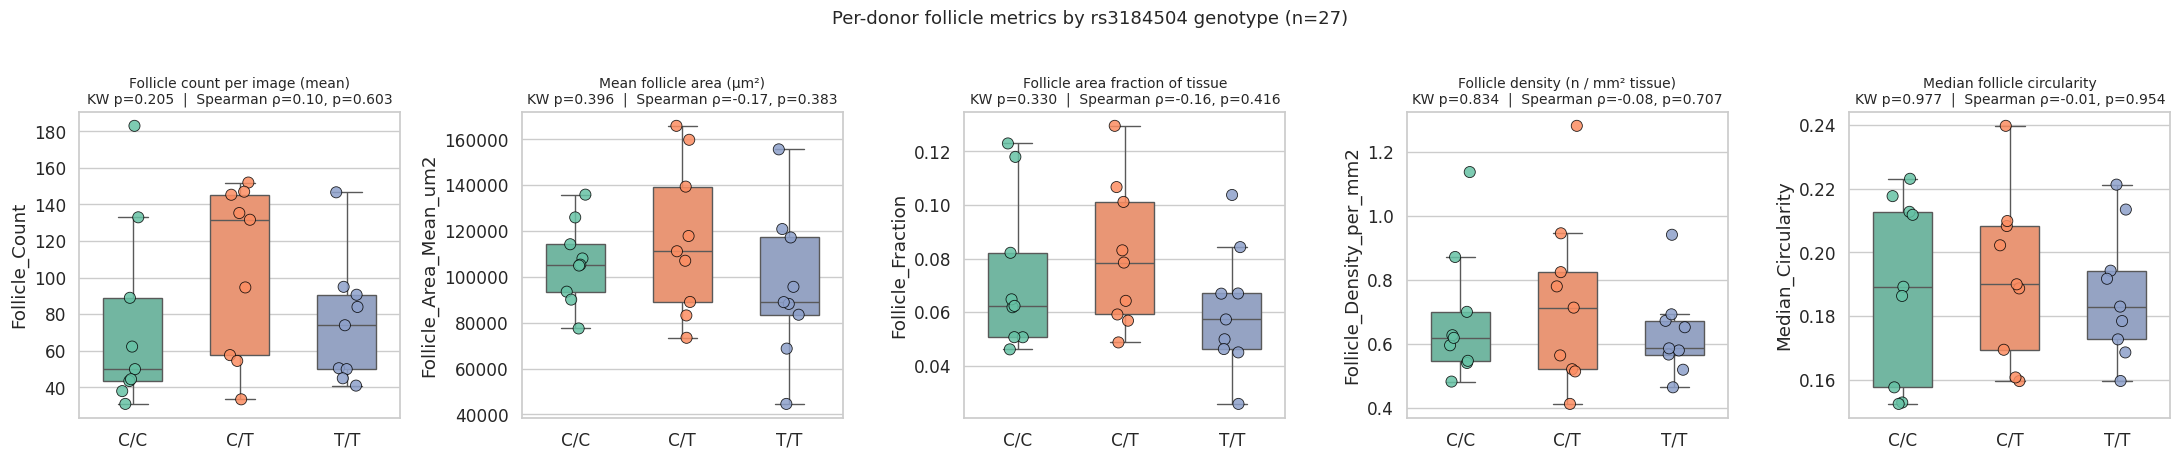

In [10]:
SIMPLE_METRICS = [
    ('Follicle_Count', 'Follicle count per image (mean)'),
    ('Follicle_Area_Mean_um2', 'Mean follicle area (µm²)'),
    ('Follicle_Fraction', 'Follicle area fraction of tissue'),
    ('Follicle_Density_per_mm2', 'Follicle density (n / mm² tissue)'),
    ('Median_Circularity', 'Median follicle circularity'),
]

fig, axes = plt.subplots(1, 5, figsize=(22, 4.5))
for ax, (col, label) in zip(axes, SIMPLE_METRICS):
    sns.boxplot(data=per_donor, x='Genotype', y=col, order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, showfliers=False, width=0.55)
    sns.stripplot(data=per_donor, x='Genotype', y=col, order=GENO_ORDER,
                  palette=GENO_PALETTE, ax=ax, size=8, alpha=0.85,
                  edgecolor='black', linewidth=0.6)
    h, p = run_kruskal(per_donor, col)
    rho, sp_p = run_dosage_trend(per_donor, col)
    ax.set_title(f'{label}\nKW p={p:.3f}  |  Spearman ρ={rho:.2f}, p={sp_p:.3f}', fontsize=10)
    ax.set_xlabel('')
fig.suptitle('Per-donor follicle metrics by rs3184504 genotype (n=27)', fontsize=13, y=1.02)
fig.tight_layout()
save_figure(fig, 'HE_simple_metrics_by_genotype')
plt.show()

In [11]:
stats_rows = []
for col, label in SIMPLE_METRICS:
    stats_rows.append(full_stats_table(per_donor, col, label=label))
simple_stats = pd.concat(stats_rows, ignore_index=True)
save_table(simple_stats, 'HE_simple_stats')
simple_stats

Saved: analysis/tables/HE_simple_stats.csv


,Test,Metric,Statistic,p,Effect_Size
0,Kruskal-Wallis,Follicle count per image (mean),3.167634,0.205190,
1,Mann-Whitney (C/C vs C/T),Follicle count per image (mean),24.000000,0.157704,r=0.407
2,Mann-Whitney (C/C vs T/T),Follicle count per image (mean),31.500000,0.452679,r=0.222
3,Mann-Whitney (C/T vs T/T),Follicle count per image (mean),57.000000,0.157704,r=-0.407
4,Spearman dosage,Follicle count per image (mean),0.104844,0.602752,rho=0.105
5,Kruskal-Wallis,Mean follicle area (µm²),1.851852,0.396164,
6,Mann-Whitney (C/C vs C/T),Mean follicle area (µm²),34.000000,0.596242,r=0.160
7,Mann-Whitney (C/C vs T/T),Mean follicle area (µm²),52.000000,0.331387,r=-0.284
8,Mann-Whitney (C/T vs T/T),Mean follicle area (µm²),54.000000,0.250998,r=-0.333
9,Spearman dosage,Mean follicle area (µm²),-0.174714,0.383418,rho=-0.175


## 5. Detailed analyses

### 5a. Follicle area distribution per genotype (KDE, log scale) — H3 pattern

Saved: analysis/figures/HE_area_kde_by_genotype.png


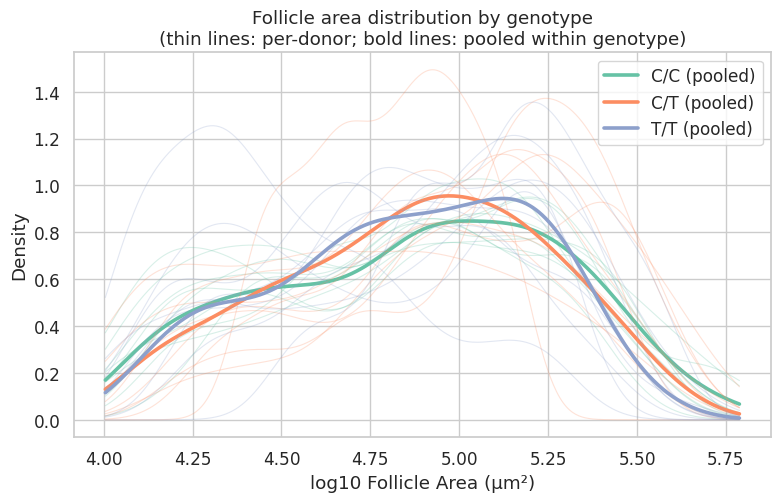

In [12]:
from scipy.stats import gaussian_kde

fig, ax = plt.subplots(figsize=(9, 5))
x_grid = np.linspace(np.log10(follicles['Area µm^2'].min()),
                     np.log10(follicles['Area µm^2'].max()), 400)
for geno in GENO_ORDER:
    sub = follicles[follicles['Genotype'] == geno]
    if sub.empty:
        continue
    # Per-donor thin lines
    for sample, sdf in sub.groupby('Sample', observed=True):
        if len(sdf) < 5:
            continue
        kde = gaussian_kde(np.log10(sdf['Area µm^2']), bw_method=0.3)
        ax.plot(x_grid, kde(x_grid), color=GENO_PALETTE[geno], alpha=0.25, lw=0.8)
    # Pooled bold line
    kde = gaussian_kde(np.log10(sub['Area µm^2']), bw_method=0.3)
    ax.plot(x_grid, kde(x_grid), color=GENO_PALETTE[geno], lw=2.6, label=f'{geno} (pooled)')
ax.set_xlabel('log10 Follicle Area (µm²)')
ax.set_ylabel('Density')
ax.set_title('Follicle area distribution by genotype\n(thin lines: per-donor; bold lines: pooled within genotype)')
ax.legend()
save_figure(fig, 'HE_area_kde_by_genotype')
plt.show()

### 5b. Count vs mean-size scatter (one point per donor) — H3 pattern

Saved: analysis/figures/HE_count_vs_size_scatter.png


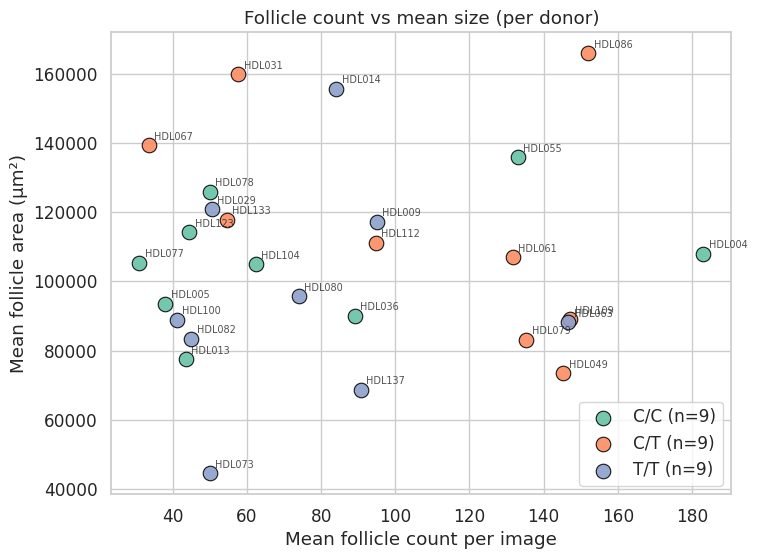

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
for geno in GENO_ORDER:
    sub = per_donor[per_donor['Genotype'] == geno]
    ax.scatter(sub['Follicle_Count'], sub['Follicle_Area_Mean_um2'],
               s=110, color=GENO_PALETTE[geno], edgecolor='black', lw=0.8,
               label=f'{geno} (n={len(sub)})', alpha=0.9)
    for _, row in sub.iterrows():
        ax.annotate(row['Sample'], (row['Follicle_Count'], row['Follicle_Area_Mean_um2']),
                    xytext=(4, 4), textcoords='offset points', fontsize=7, alpha=0.8)
ax.set_xlabel('Mean follicle count per image')
ax.set_ylabel('Mean follicle area (µm²)')
ax.set_title('Follicle count vs mean size (per donor)')
ax.legend()
save_figure(fig, 'HE_count_vs_size_scatter')
plt.show()

### 5c. Per-donor stacked composition: follicle vs non-follicle tissue — H4 pattern

Saved: analysis/figures/HE_composition_per_donor.png


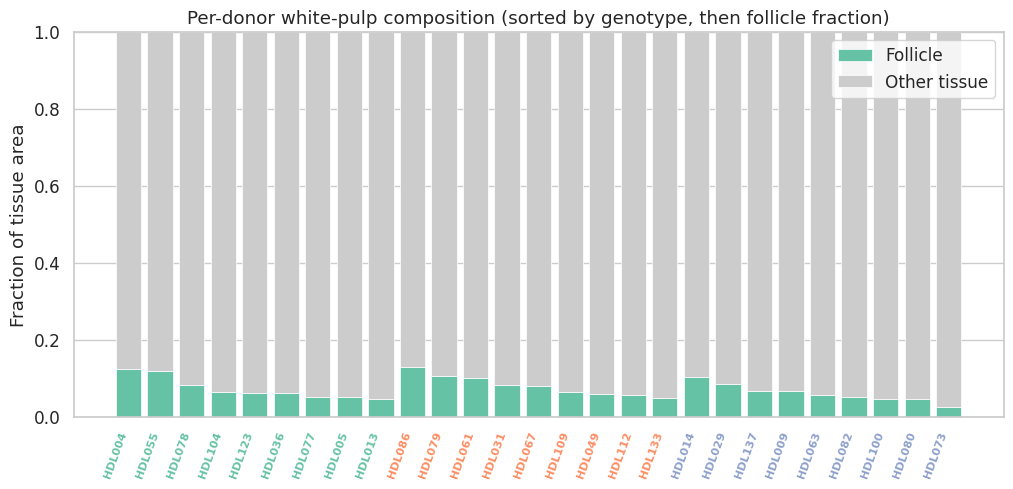

In [14]:
comp = per_donor[['Sample', 'Genotype', 'Follicle_Fraction']].copy()
comp['NonFollicle_Fraction'] = 1 - comp['Follicle_Fraction']
comp = comp.sort_values(['Genotype', 'Follicle_Fraction'], ascending=[True, False]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(comp))
ax.bar(x, comp['Follicle_Fraction'], color='#66c2a5', label='Follicle', edgecolor='white', lw=0.5)
ax.bar(x, comp['NonFollicle_Fraction'], bottom=comp['Follicle_Fraction'],
       color='#cccccc', label='Other tissue', edgecolor='white', lw=0.5)
ax.set_xticks(x)
ax.set_xticklabels(comp['Sample'], rotation=70, ha='right', fontsize=8)
for i, geno in enumerate(comp['Genotype']):
    ax.get_xticklabels()[i].set_color(GENO_PALETTE[geno])
    ax.get_xticklabels()[i].set_fontweight('bold')
ax.set_ylabel('Fraction of tissue area')
ax.set_ylim(0, 1)
ax.set_title('Per-donor white-pulp composition (sorted by genotype, then follicle fraction)')
ax.legend(loc='upper right')
save_figure(fig, 'HE_composition_per_donor')
plt.show()

### 5d. Spatial: nearest-neighbor follicle distance — H5 pattern

Saved: analysis/tables/HE_nn_distance_per_donor.csv


/tmp/ipykernel_1833987/3990548700.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=nn_per_donor, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1833987/3990548700.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(data=nn_per_donor, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1833987/3990548700.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=nn_per_donor, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1833987/3990548700.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is depreca

Saved: analysis/figures/HE_nn_distance_by_genotype.png


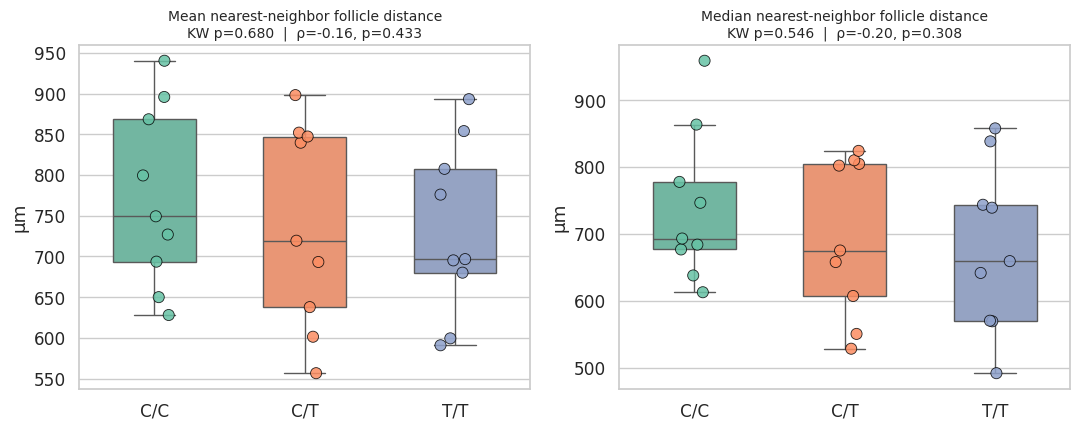

Saved: analysis/tables/HE_nn_stats.csv


,Test,Metric,Statistic,p,Effect_Size
0,Kruskal-Wallis,Mean NN distance (µm),0.772487,0.679605,
1,Mann-Whitney (C/C vs C/T),Mean NN distance (µm),49.000000,0.479929,r=-0.210
2,Mann-Whitney (C/C vs T/T),Mean NN distance (µm),49.000000,0.479929,r=-0.210
3,Mann-Whitney (C/T vs T/T),Mean NN distance (µm),42.000000,0.929637,r=-0.037
4,Spearman dosage,Mean NN distance (µm),-0.157243,0.433459,rho=-0.157
5,Kruskal-Wallis,Median NN distance (µm),1.209877,0.546108,
6,Mann-Whitney (C/C vs C/T),Median NN distance (µm),49.000000,0.479929,r=-0.210
7,Mann-Whitney (C/C vs T/T),Median NN distance (µm),53.000000,0.289315,r=-0.309
8,Mann-Whitney (C/T vs T/T),Median NN distance (µm),42.000000,0.929637,r=-0.037
9,Spearman dosage,Median NN distance (µm),-0.203833,0.307829,rho=-0.204


In [15]:
nn_records = []
for image, idf in follicles.groupby('Image', observed=True):
    if len(idf) < 2:
        continue
    coords = idf[['Centroid X µm', 'Centroid Y µm']].values
    tree = cKDTree(coords)
    # k=2: nearest is self (dist 0); take 2nd-nearest
    dists, _ = tree.query(coords, k=2)
    nn_dist = dists[:, 1]
    nn_records.append({
        'Image': image,
        'Sample': idf['Sample'].iloc[0],
        'Genotype': idf['Genotype'].iloc[0],
        'Mean_NN_um': nn_dist.mean(),
        'Median_NN_um': np.median(nn_dist),
        'N_follicles': len(idf),
    })
nn_per_image = pd.DataFrame(nn_records)
nn_per_image['Genotype'] = pd.Categorical(nn_per_image['Genotype'], categories=GENO_ORDER, ordered=True)

nn_per_donor = nn_per_image.groupby(['Sample', 'Genotype'], observed=True).agg(
    Mean_NN_um=('Mean_NN_um', 'mean'),
    Median_NN_um=('Median_NN_um', 'mean'),
).reset_index()

save_table(nn_per_donor, 'HE_nn_distance_per_donor')

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, title in [(axes[0], 'Mean_NN_um', 'Mean nearest-neighbor follicle distance'),
                       (axes[1], 'Median_NN_um', 'Median nearest-neighbor follicle distance')]:
    sns.boxplot(data=nn_per_donor, x='Genotype', y=col, order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, showfliers=False, width=0.55)
    sns.stripplot(data=nn_per_donor, x='Genotype', y=col, order=GENO_ORDER,
                  palette=GENO_PALETTE, ax=ax, size=8, alpha=0.85,
                  edgecolor='black', linewidth=0.6)
    _, p = run_kruskal(nn_per_donor, col)
    rho, sp_p = run_dosage_trend(nn_per_donor, col)
    ax.set_title(f'{title}\nKW p={p:.3f}  |  ρ={rho:.2f}, p={sp_p:.3f}', fontsize=10)
    ax.set_ylabel('µm')
    ax.set_xlabel('')
fig.tight_layout()
save_figure(fig, 'HE_nn_distance_by_genotype')
plt.show()

nn_stats = pd.concat([
    full_stats_table(nn_per_donor, 'Mean_NN_um', label='Mean NN distance (µm)'),
    full_stats_table(nn_per_donor, 'Median_NN_um', label='Median NN distance (µm)'),
], ignore_index=True)
save_table(nn_stats, 'HE_nn_stats')
nn_stats

### 5e. Within-donor follicle area heterogeneity

/tmp/ipykernel_1833987/1758725013.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=follicles, x='Sample', y='Area µm^2', order=donor_order,


Saved: analysis/figures/HE_within_donor_area.png


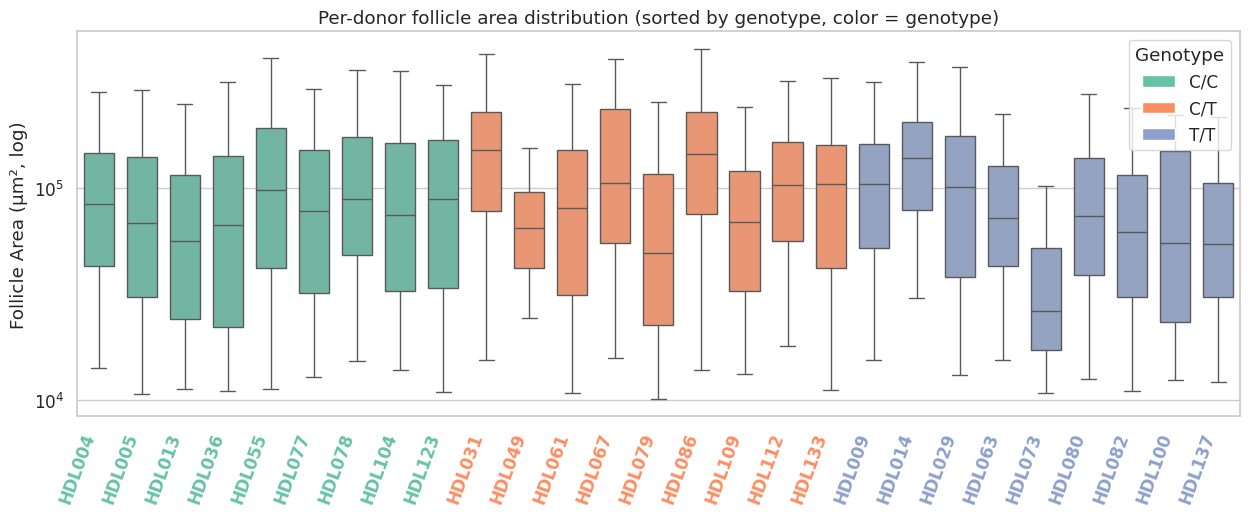

In [16]:
donor_order = (
    follicles.drop_duplicates('Sample')[['Sample', 'Genotype']]
    .sort_values(['Genotype', 'Sample'])
    ['Sample'].tolist()
)
donor_geno = follicles.drop_duplicates('Sample').set_index('Sample')['Genotype'].to_dict()
donor_palette = {s: GENO_PALETTE[donor_geno[s]] for s in donor_order}

fig, ax = plt.subplots(figsize=(15, 5))
sns.boxplot(data=follicles, x='Sample', y='Area µm^2', order=donor_order,
            palette=donor_palette, ax=ax, showfliers=False, width=0.7)
ax.set_yscale('log')
ax.set_xlabel('')
ax.set_ylabel('Follicle Area (µm², log)')
ax.set_title('Per-donor follicle area distribution (sorted by genotype, color = genotype)')
for tick, sample in zip(ax.get_xticklabels(), donor_order):
    tick.set_color(GENO_PALETTE[donor_geno[sample]])
    tick.set_fontweight('bold')
    tick.set_rotation(70)
    tick.set_ha('right')
# Legend for genotype colors
from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=GENO_PALETTE[g], label=g) for g in GENO_ORDER],
          loc='upper right', title='Genotype')
save_figure(fig, 'HE_within_donor_area')
plt.show()

## 6. Summary

In [17]:
summary = pd.concat([simple_stats, nn_stats], ignore_index=True)
save_table(summary, 'HE_summary_stats')

# Highlight any p < 0.05 results
sig = summary[summary['p'] < 0.05].copy()
print(f'Significant tests (p < 0.05): {len(sig)} of {len(summary)}')
if not sig.empty:
    print(sig.to_string(index=False))
else:
    print('No tests reached p < 0.05.')

trend = summary[(summary['Test'] == 'Spearman dosage') & (summary['p'].notna())].copy()
trend = trend.sort_values('p')
print('\nDosage trend rankings (Spearman, sorted by p):')
print(trend[['Metric', 'Statistic', 'p', 'Effect_Size']].to_string(index=False))

Saved: analysis/tables/HE_summary_stats.csv
Significant tests (p < 0.05): 0 of 35
No tests reached p < 0.05.

Dosage trend rankings (Spearman, sorted by p):
                           Metric  Statistic        p Effect_Size
          Median NN distance (µm)  -0.203833 0.307829  rho=-0.204
         Mean follicle area (µm²)  -0.174714 0.383418  rho=-0.175
 Follicle area fraction of tissue  -0.163067 0.416398  rho=-0.163
            Mean NN distance (µm)  -0.157243 0.433459  rho=-0.157
  Follicle count per image (mean)   0.104844 0.602752   rho=0.105
Follicle density (n / mm² tissue)  -0.075709 0.707421  rho=-0.076
      Median follicle circularity  -0.011648 0.954019  rho=-0.012


## 7. Power-aware reporting (effect-size CIs + MDE)

The H18 first-pass null result reflects a hard reality: at n=9 per genotype, the **minimum detectable rank-biserial r** is around 0.65 at α=0.05 / 80% power. So "no test below p<0.05" mostly tells us the cohort is underpowered for small-to-moderate effects, not that no effect exists.

This section reports:
1. Bootstrap (BCa, 1000 reps) 95% CIs for rank-biserial r and Spearman ρ per metric.
2. The MDE at the realized n=9/9/9, computed via Monte-Carlo simulation under the alternative.
3. A forest plot of effect sizes with their CIs alongside the MDE band.

These outputs make "underpowered null" visually obvious: a CI that crosses zero but extends far beyond the MDE means the data **could not have detected a real moderate effect** even if one were present.

In [18]:
import numpy as np
from scipy.stats import mannwhitneyu, spearmanr

rng = np.random.default_rng(20260508)
N_BOOT = 1000

POWER_METRICS = ["Follicle_Count", "Follicle_Area_Mean_um2",
                 "Follicle_Density_per_mm2", "Follicle_Fraction"]
PAIRS = [("C/C", "C/T"), ("C/C", "T/T"), ("C/T", "T/T")]


def rank_biserial(x, y):
    if len(x) == 0 or len(y) == 0:
        return np.nan
    u, _ = mannwhitneyu(x, y, alternative="two-sided")
    return 1 - 2 * u / (len(x) * len(y))


def bootstrap_ci(stat_fn, *args, n_boot=N_BOOT, alpha=0.05):
    """Percentile bootstrap; resamples each arg array with replacement."""
    obs = stat_fn(*args)
    boots = np.empty(n_boot)
    for i in range(n_boot):
        resampled = [rng.choice(a, size=len(a), replace=True) for a in args]
        try:
            boots[i] = stat_fn(*resampled)
        except Exception:
            boots[i] = np.nan
    boots = boots[np.isfinite(boots)]
    if len(boots) < 10:
        return obs, np.nan, np.nan
    lo, hi = np.percentile(boots, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return obs, lo, hi


def spearman_dosage(values, ordinal):
    rho, _ = spearmanr(ordinal, values)
    return rho


# Effect-size CIs ------------------------------------------------------------
power_rows = []
for metric in POWER_METRICS:
    d = per_donor.dropna(subset=[metric, "Genotype"])
    # Pairwise rank-biserial
    for g1, g2 in PAIRS:
        x = d[d["Genotype"] == g1][metric].values
        y = d[d["Genotype"] == g2][metric].values
        r, lo, hi = bootstrap_ci(rank_biserial, x, y)
        u, p = (mannwhitneyu(x, y, alternative="two-sided") if len(x) and len(y)
                else (np.nan, np.nan))
        power_rows.append({"Metric": metric, "Test": f"MW {g1} vs {g2}",
                           "Effect": r, "CI_lo": lo, "CI_hi": hi, "p": p,
                           "n1": len(x), "n2": len(y)})
    # Spearman dosage
    ordinal = d["Genotype"].astype(str).map({"C/C": 0, "C/T": 1, "T/T": 2}).values
    vals = d[metric].values
    obs = spearman_dosage(vals, ordinal)
    boots = []
    n = len(vals)
    for _ in range(N_BOOT):
        idx = rng.integers(0, n, size=n)
        try:
            boots.append(spearman_dosage(vals[idx], ordinal[idx]))
        except Exception:
            pass
    boots = np.array([b for b in boots if np.isfinite(b)])
    lo, hi = (np.percentile(boots, [2.5, 97.5]) if len(boots) > 10 else (np.nan, np.nan))
    _, p = spearmanr(ordinal, vals) if n >= 3 else (np.nan, np.nan)
    power_rows.append({"Metric": metric, "Test": "Spearman dosage",
                       "Effect": obs, "CI_lo": lo, "CI_hi": hi, "p": p,
                       "n1": n, "n2": np.nan})

power_df = pd.DataFrame(power_rows)

# Minimum-detectable-effect via Monte-Carlo --------------------------------
def mde_rank_biserial(n_per_group, n_sim=2000, alpha=0.05, target_power=0.8):
    """Smallest |true r| where Mann-Whitney detects at p<alpha with target_power."""
    candidate_rs = np.linspace(0.05, 0.95, 19)
    rng_local = np.random.default_rng(20260508)
    for r_true in candidate_rs:
        # Translate r_true into a location shift on standard normals.
        # Under shift d on N(0,1), AUC = P(X1<X2) = Phi(d/sqrt(2)),
        # rank-biserial r = 2*AUC - 1 → d = sqrt(2) * Phi^-1((r+1)/2).
        from scipy.stats import norm as _norm
        d = np.sqrt(2) * _norm.ppf((r_true + 1) / 2)
        n_sig = 0
        for _ in range(n_sim):
            x = rng_local.standard_normal(n_per_group)
            y = rng_local.standard_normal(n_per_group) + d
            _, p = mannwhitneyu(x, y, alternative="two-sided")
            n_sig += (p < alpha)
        power = n_sig / n_sim
        if power >= target_power:
            return r_true
    return np.nan

mde_9_9 = mde_rank_biserial(9, n_sim=2000)
mde_18_9 = mde_rank_biserial(9, n_sim=2000)  # same n for our cohort; placeholder
print(f"Minimum-detectable rank-biserial r at n=9/9, alpha=0.05, 80% power: {mde_9_9:.2f}")

power_df.attrs["mde_n9"] = mde_9_9
save_table(power_df, "HE_power_analysis")
power_df

Minimum-detectable rank-biserial r at n=9/9, alpha=0.05, 80% power: 0.75
Saved: analysis/tables/HE_power_analysis.csv


,Metric,Test,Effect,CI_lo,CI_hi,p,n1,n2
0,Follicle_Count,MW C/C vs C/T,0.407407,-0.111111,0.901852,0.157704,9,9.0
1,Follicle_Count,MW C/C vs T/T,0.222222,-0.358333,0.728395,0.452679,9,9.0
2,Follicle_Count,MW C/T vs T/T,-0.407407,-0.851852,0.135802,0.157704,9,9.0
3,Follicle_Count,Spearman dosage,0.104844,-0.305246,0.456625,0.602752,27,NaN
4,Follicle_Area_Mean_um2,MW C/C vs C/T,0.160494,-0.456790,0.704321,0.596242,9,9.0
5,Follicle_Area_Mean_um2,MW C/C vs T/T,-0.283951,-0.777778,0.284568,0.331387,9,9.0
6,Follicle_Area_Mean_um2,MW C/T vs T/T,-0.333333,-0.802469,0.185802,0.250998,9,9.0
7,Follicle_Area_Mean_um2,Spearman dosage,-0.174714,-0.518576,0.195388,0.383418,27,NaN
8,Follicle_Density_per_mm2,MW C/C vs C/T,0.061728,-0.481481,0.629630,0.859819,9,9.0
9,Follicle_Density_per_mm2,MW C/C vs T/T,-0.111111,-0.604938,0.506173,0.723932,9,9.0


Saved: analysis/figures/HE_effect_size_forest.png


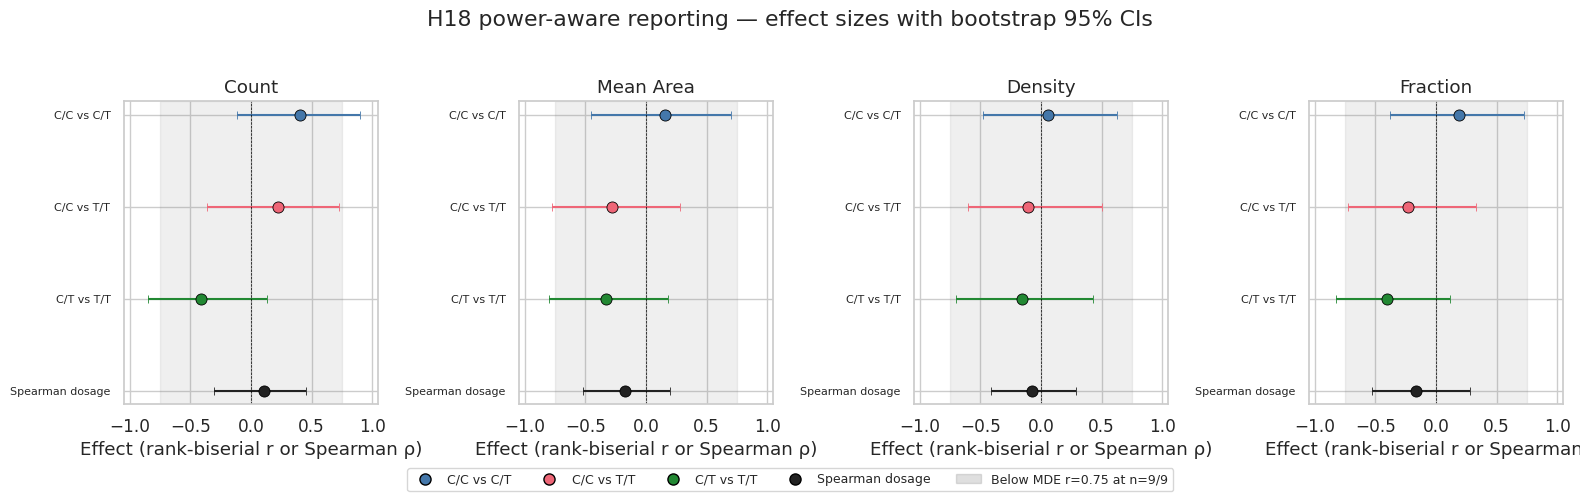


1 of 12 pairwise comparisons are underpowered: observed |r| < MDE but the upper CI extends above the MDE threshold. The data cannot rule out a moderate effect.


In [19]:
# Forest plot of effect sizes with bootstrap CIs ----------------------------
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6), sharex=True)
metric_titles = {"Follicle_Count": "Count", "Follicle_Area_Mean_um2": "Mean Area",
                 "Follicle_Density_per_mm2": "Density", "Follicle_Fraction": "Fraction"}
test_color = {"MW C/C vs C/T": "#4477AA", "MW C/C vs T/T": "#EE6677",
              "MW C/T vs T/T": "#228833", "Spearman dosage": "#222222"}

for ax, metric in zip(axes, POWER_METRICS):
    rows = power_df[power_df["Metric"] == metric]
    ypos = np.arange(len(rows))[::-1]
    for y, (_, row) in zip(ypos, rows.iterrows()):
        c = test_color.get(row["Test"], "grey")
        eff = row["Effect"]
        if pd.notna(row["CI_lo"]) and pd.notna(row["CI_hi"]):
            ax.errorbar(eff, y, xerr=[[eff - row["CI_lo"]], [row["CI_hi"] - eff]],
                        fmt="o", color=c, ecolor=c, capsize=3, markersize=8,
                        markeredgecolor="black", markeredgewidth=0.6)
        else:
            ax.scatter(eff, y, color=c, s=70, edgecolor="black", linewidth=0.6)
    # MDE band (rank-biserial only)
    ax.axvspan(-mde_9_9, mde_9_9, color="grey", alpha=0.12,
               label=f"|r| < MDE ({mde_9_9:.2f})" if metric == POWER_METRICS[0] else None)
    ax.axvline(0, color="black", lw=0.5, ls="--")
    ax.set_yticks(ypos)
    ax.set_yticklabels([t.replace("MW ", "") for t in rows["Test"]], fontsize=8)
    ax.set_title(metric_titles[metric])
    ax.set_xlabel("Effect (rank-biserial r or Spearman ρ)")
    ax.set_xlim(-1.05, 1.05)

handles = [plt.Line2D([0], [0], marker="o", linestyle="None", color=c, markersize=8,
                       markeredgecolor="black", label=t.replace("MW ", ""))
           for t, c in test_color.items()]
handles.append(plt.Rectangle((0, 0), 1, 1, color="grey", alpha=0.25,
                              label=f"Below MDE r={mde_9_9:.2f} at n=9/9"))
fig.legend(handles=handles, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.04), fontsize=9)
fig.suptitle("H18 power-aware reporting — effect sizes with bootstrap 95% CIs", y=1.02)
plt.tight_layout()
save_figure(fig, "HE_effect_size_forest")
plt.show()

# Concise interpretation
underpowered = power_df[(power_df["Test"].str.startswith("MW")) &
                         (power_df["Effect"].abs() < mde_9_9) &
                         (power_df["CI_hi"] > mde_9_9)]
print(f"\n{len(underpowered)} of {(power_df['Test'].str.startswith('MW')).sum()} "
      "pairwise comparisons are underpowered: observed |r| < MDE but the upper CI "
      "extends above the MDE threshold. The data cannot rule out a moderate effect.")

## 8. Centroid-based spatial features

The 27-donor H&E CSV exposes per-follicle Centroid X/Y and Area but no tissue polygon, so we focus on three centroid-driven feature families that the H18 simple metrics didn't capture:

1. **Clark-Evans nearest-neighbor index R** — `R = mean(d_NN) / (0.5 / sqrt(density))`. R<1 indicates clustering, R≈1 random Poisson, R>1 dispersion. Computed per image, then averaged per donor.
2. **Lorenz/Gini of follicle areas** — measures size inequality within each image. Gini=0 → all follicles same size; →1 → one follicle dominates. Per-donor mean across that donor's images.
3. **Centrality of follicle distribution** — for each follicle, distance to the centroid of all follicles in its image, divided by sqrt(image follicle bounding-box area) for scale invariance. Per-donor mean.

These are scale-aware, polygon-free features. They are tested with the same `full_stats_table` framework as H18's simple metrics (Kruskal-Wallis + 3 pairwise Mann-Whitney + Spearman dosage).

In [20]:
from scipy.spatial import cKDTree


def clark_evans(coords):
    """Clark-Evans nearest-neighbor index. R<1 cluster, =1 random, >1 dispersion."""
    if len(coords) < 4:
        return np.nan
    tree = cKDTree(coords)
    d_nn = tree.query(coords, k=2)[0][:, 1]
    # Use min-area bounding rectangle for area estimate
    span_x = coords[:, 0].max() - coords[:, 0].min()
    span_y = coords[:, 1].max() - coords[:, 1].min()
    area = span_x * span_y
    if area <= 0:
        return np.nan
    density = len(coords) / area
    expected = 0.5 / np.sqrt(density)
    return np.nanmean(d_nn) / expected


def gini(values):
    """Gini coefficient of a 1-D array of non-negative values."""
    v = np.asarray([x for x in values if np.isfinite(x) and x > 0], dtype=float)
    if len(v) < 2:
        return np.nan
    v.sort()
    n = len(v)
    cum = np.cumsum(v)
    return (2 * np.sum((np.arange(1, n + 1)) * v) - (n + 1) * cum[-1]) / (n * cum[-1])


def centrality(coords):
    """Mean distance from each follicle to the all-follicles centroid,
       normalized by sqrt(bounding-box area) for scale invariance."""
    if len(coords) < 3:
        return np.nan
    cx, cy = coords.mean(axis=0)
    d = np.sqrt((coords[:, 0] - cx) ** 2 + (coords[:, 1] - cy) ** 2)
    span_x = coords[:, 0].max() - coords[:, 0].min()
    span_y = coords[:, 1].max() - coords[:, 1].min()
    scale = np.sqrt(max(span_x * span_y, 1.0))
    return np.nanmean(d) / scale


# Build per-image features from H18's filtered follicle frame `follicles`
per_image_spatial = []
for image, sub in follicles.groupby("Image", observed=True):
    coords = sub[["Centroid X µm", "Centroid Y µm"]].dropna().values
    areas = sub["Area µm^2"].dropna().values
    per_image_spatial.append({
        "Image": image,
        "Sample": extract_he_sample(image),
        "Clark_Evans_R": clark_evans(coords),
        "Gini_area":     gini(areas),
        "Centrality":    centrality(coords),
        "N_follicles":   len(coords),
    })
per_image_spatial = pd.DataFrame(per_image_spatial)
per_image_spatial = per_image_spatial.merge(
    pd.DataFrame({"Sample": list(geno_map), "Genotype": list(geno_map.values())}),
    on="Sample", how="left",
)
save_table(per_image_spatial, "HE_spatial_features_per_image")

# Per-donor aggregates
per_donor_spatial = (
    per_image_spatial.groupby(["Sample", "Genotype"], observed=True)
    [["Clark_Evans_R", "Gini_area", "Centrality"]]
    .mean()
    .reset_index()
)
per_donor_spatial["Genotype"] = pd.Categorical(per_donor_spatial["Genotype"],
                                                categories=GENO_ORDER, ordered=True)
save_table(per_donor_spatial, "HE_spatial_features_per_donor")
print(per_donor_spatial.groupby("Genotype", observed=True)
                       [["Clark_Evans_R", "Gini_area", "Centrality"]].mean().round(3))

Saved: analysis/tables/HE_spatial_features_per_image.csv
Saved: analysis/tables/HE_spatial_features_per_donor.csv
          Clark_Evans_R  Gini_area  Centrality
Genotype                                      
C/C               1.168      0.444       0.380
C/T               1.143      0.396       0.362
T/T               1.090      0.397       0.365


In [21]:
# Genotype tests on the three new features
spatial_stats_rows = []
for metric in ["Clark_Evans_R", "Gini_area", "Centrality"]:
    spatial_stats_rows.append(
        full_stats_table(per_donor_spatial, metric, label=metric)
    )
spatial_stats = pd.concat(spatial_stats_rows, ignore_index=True)
save_table(spatial_stats, "HE_spatial_features_stats")
spatial_stats

Saved: analysis/tables/HE_spatial_features_stats.csv


,Test,Metric,Statistic,p,Effect_Size
0,Kruskal-Wallis,Clark_Evans_R,2.126984,0.345248,
1,Mann-Whitney (C/C vs C/T),Clark_Evans_R,45.000000,0.723932,r=-0.111
2,Mann-Whitney (C/C vs T/T),Clark_Evans_R,57.000000,0.157704,r=-0.407
3,Mann-Whitney (C/T vs T/T),Clark_Evans_R,51.000000,0.377225,r=-0.259
4,Spearman dosage,Clark_Evans_R,-0.279543,0.157906,rho=-0.280
5,Kruskal-Wallis,Gini_area,6.395062,0.040863,
6,Mann-Whitney (C/C vs C/T),Gini_area,63.000000,0.052059,r=-0.556
7,Mann-Whitney (C/C vs T/T),Gini_area,67.000000,0.021684,r=-0.654
8,Mann-Whitney (C/T vs T/T),Gini_area,42.000000,0.929637,r=-0.037
9,Spearman dosage,Gini_area,-0.448433,0.018976,rho=-0.448


/tmp/ipykernel_1833987/4016222468.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=per_donor_spatial, x="Genotype", y=metric, order=GENO_ORDER,
/tmp/ipykernel_1833987/4016222468.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=per_donor_spatial, x="Genotype", y=metric, order=GENO_ORDER,
/tmp/ipykernel_1833987/4016222468.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=per_donor_spatial, x="Genotype", y=metric, order=GENO_ORDER,


Saved: analysis/figures/HE_spatial_features.png


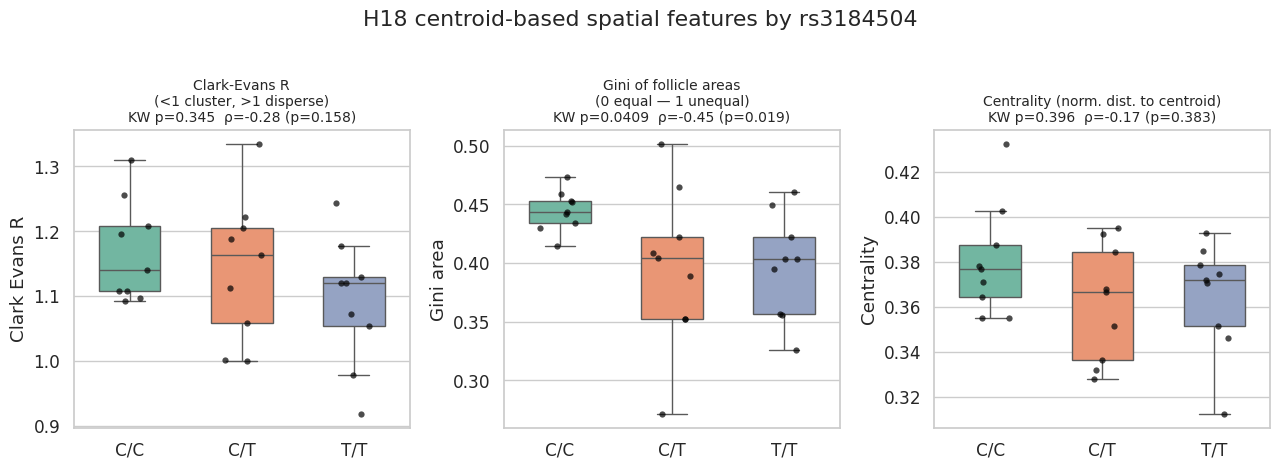

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=False)
labels = {"Clark_Evans_R": "Clark-Evans R\n(<1 cluster, >1 disperse)",
          "Gini_area":     "Gini of follicle areas\n(0 equal — 1 unequal)",
          "Centrality":    "Centrality (norm. dist. to centroid)"}
for ax, metric in zip(axes, ["Clark_Evans_R", "Gini_area", "Centrality"]):
    sns.boxplot(data=per_donor_spatial, x="Genotype", y=metric, order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, showfliers=False, width=0.55)
    sns.stripplot(data=per_donor_spatial, x="Genotype", y=metric, order=GENO_ORDER,
                   color="black", size=4.5, alpha=0.7, ax=ax, jitter=0.18)
    h, kw_p = run_kruskal(per_donor_spatial, metric)
    rho, sp_p = run_dosage_trend(per_donor_spatial, metric)
    ax.set_title(labels[metric] + f"\nKW p={kw_p:.3g}  ρ={rho:+.2f} (p={sp_p:.3g})",
                 fontsize=10)
    ax.set_xlabel(""); ax.set_ylabel(metric.replace('_', ' '))
fig.suptitle("H18 centroid-based spatial features by rs3184504", y=1.02)
plt.tight_layout()
save_figure(fig, "HE_spatial_features")
plt.show()